In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

In [5]:
df = pd.read_csv("../datasets/heart_disease_uci.csv")

df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [6]:
print("Shape:", df.shape)

df.info()

Shape: (920, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [7]:
df.describe(include="all")

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
count,920.000000,920.000000,920,920,920,861.000000,890.000000,830,918,865.000000,865,858.000000,611,309.000000,434,920.000000
unique,NaN,NaN,2,4,4,NaN,NaN,2,3,NaN,2,NaN,3,NaN,3,NaN
top,NaN,NaN,Male,Cleveland,asymptomatic,NaN,NaN,False,normal,NaN,False,NaN,flat,NaN,normal,NaN
freq,NaN,NaN,726,304,496,NaN,NaN,692,551,NaN,528,NaN,345,NaN,196,NaN
mean,460.500000,53.510870,NaN,NaN,NaN,132.132404,199.130337,NaN,NaN,137.545665,NaN,0.878788,NaN,0.676375,NaN,0.995652
std,265.725422,9.424685,NaN,NaN,NaN,19.066070,110.780810,NaN,NaN,25.926276,NaN,1.091226,NaN,0.935653,NaN,1.142693
min,1.000000,28.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,60.000000,NaN,-2.600000,NaN,0.000000,NaN,0.000000
25%,230.750000,47.000000,NaN,NaN,NaN,120.000000,175.000000,NaN,NaN,120.000000,NaN,0.000000,NaN,0.000000,NaN,0.000000
50%,460.500000,54.000000,NaN,NaN,NaN,130.000000,223.000000,NaN,NaN,140.000000,NaN,0.500000,NaN,0.000000,NaN,1.000000
75%,690.250000,60.000000,NaN,NaN,NaN,140.000000,268.000000,NaN,NaN,157.000000,NaN,1.500000,NaN,1.000000,NaN,2.000000


In [8]:
missing = df.isnull().sum()

missing = missing[missing > 0]

missing.sort_values(ascending=False)

ca          611
thal        486
slope       309
fbs          90
oldpeak      62
trestbps     59
exang        55
thalch       55
chol         30
restecg       2
dtype: int64

In [9]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent[missing_percent > 0]

missing_percent.sort_values(ascending=False)

ca          66.413043
thal        52.826087
slope       33.586957
fbs          9.782609
oldpeak      6.739130
trestbps     6.413043
exang        5.978261
thalch       5.978261
chol         3.260870
restecg      0.217391
dtype: float64

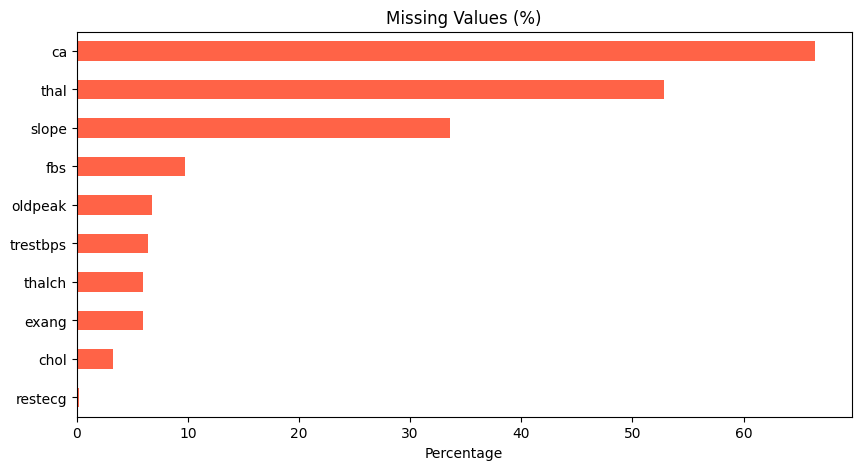

In [10]:
plt.figure(figsize=(10,5))

missing_percent.sort_values().plot(
    kind="barh",
    color="tomato"
)

plt.title("Missing Values (%)")

plt.xlabel("Percentage")

plt.show()

In [11]:
df = df.drop(
    columns=[
        "id",
        "ca",
        "thal"
    ]
)

In [12]:
df.isnull().sum()

age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
num           0
dtype: int64

In [13]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

print("New Shape:", df.shape)

Duplicates: 2
New Shape: (918, 13)


In [14]:
df["num"].value_counts()

num
0    410
1    265
2    108
3    107
4     28
Name: count, dtype: int64

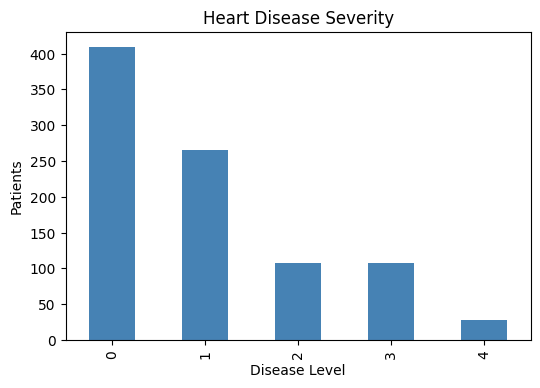

In [15]:
plt.figure(figsize=(6,4))

df["num"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue"
)

plt.title("Heart Disease Severity")

plt.xlabel("Disease Level")

plt.ylabel("Patients")

plt.show()

In [22]:
df.head()

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,num
0,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0
1,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,2
2,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,1
3,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0
4,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0


In [23]:
# ============================================
# Convert Heart Disease to Severity Classes
# ============================================

severity_mapping = {
    0: 0,   # Healthy
    1: 1,   # Mild
    2: 2,   # Moderate
    3: 3,   # Severe
    4: 3    # Merge Very Severe into Severe
}

df["target"] = df["num"].map(severity_mapping)

df.drop(columns=["num"], inplace=True)

print("Severity Distribution")
print(df["target"].value_counts().sort_index())

Severity Distribution
target
0    410
1    265
2    108
3    135
Name: count, dtype: int64


In [25]:
df.isnull().sum()

age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         29
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       307
target        0
dtype: int64

In [26]:
# Numerical columns
numerical_cols = [
    "trestbps",
    "chol",
    "thalch",
    "oldpeak"
]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns
categorical_cols = [
    "fbs",
    "restecg",
    "exang",
    "slope"
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())

age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
target      0
dtype: int64


C:\Users\varad khodave\AppData\Local\Temp\ipykernel_28832\51923420.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(df[col].mode()[0])


In [27]:
df["fbs"] = df["fbs"].replace({
    True: 1,
    False: 0
}).astype(int)

df["exang"] = df["exang"].replace({
    True: 1,
    False: 0
}).astype(int)

C:\Users\varad khodave\AppData\Local\Temp\ipykernel_28832\4011832066.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["fbs"] = df["fbs"].replace({
C:\Users\varad khodave\AppData\Local\Temp\ipykernel_28832\4011832066.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["exang"] = df["exang"].replace({


In [31]:
df.dtypes


age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs           int64
restecg      object
thalch      float64
exang         int64
oldpeak     float64
slope        object
target        int64
dtype: object

In [ ]:
# Male = 1
# Female = 0

df["sex"] = df["sex"].map({
    "Male": 1,
    "Female": 0
})

Series([], Name: count, dtype: int64)

In [34]:
df["sex"].value_counts()

Series([], Name: count, dtype: int64)

In [35]:
df = pd.get_dummies(
    df,
    columns=[
        "dataset",
        "cp",
        "restecg",
        "slope"
    ],
    drop_first=True,
    dtype=int
)

In [38]:
print(df["target"].value_counts())

target
0    410
1    265
3    135
2    108
Name: count, dtype: int64


In [39]:
X = df.drop("target", axis=1)
y = df["target"]

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (918, 18)
Labels: (918,)


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (734, 18)
Test : (184, 18)


In [41]:
# ======================================
# Machine Learning Libraries
# ======================================

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.svm import SVC

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [43]:
# ======================================
# Models
# ======================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Support Vector Machine": SVC(
        kernel="rbf"
    ),

    "XGBoost": XGBClassifier(
        objective="multi:softmax",
        num_class=4,
        random_state=42,
        eval_metric="mlogloss"
    )
}

In [44]:
# ======================================
# Train Models
# ======================================

results = []

for name, model in models.items():

    print("="*60)
    print(name)
    print("="*60)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(classification_report(y_test, predictions))

Logistic Regression


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [46]:
X = df.drop("target", axis=1)

print(X.isnull().sum()[X.isnull().sum() > 0])

sex    918
dtype: int64


In [56]:
df = pd.read_csv("../datasets/heart_disease_uci.csv")
df.drop(columns=["id", "ca", "thal"], inplace=True)

# Numerical
for col in ["trestbps", "chol", "thalch", "oldpeak"]:
    df[col] = df[col].fillna(df[col].median())

# Categorical
for col in ["fbs", "restecg", "exang", "slope"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicates
df = df.drop_duplicates()

severity_mapping = {
    0: 0,
    1: 1,
    2: 2,
    3: 3,
    4: 3
}

df["target"] = df["num"].map(severity_mapping)
df.drop(columns=["num"], inplace=True)

C:\Users\varad khodave\AppData\Local\Temp\ipykernel_28832\1576826674.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].fillna(df[col].mode()[0])


In [57]:
df["sex"] = df["sex"].replace({
    "Male": 1,
    "Female": 0
}).astype(int)

C:\Users\varad khodave\AppData\Local\Temp\ipykernel_28832\1420047567.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["sex"] = df["sex"].replace({


In [58]:
df["fbs"] = df["fbs"].replace({True: 1, False: 0}).astype(int)
df["exang"] = df["exang"].replace({True: 1, False: 0}).astype(int)

C:\Users\varad khodave\AppData\Local\Temp\ipykernel_28832\904389340.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["fbs"] = df["fbs"].replace({True: 1, False: 0}).astype(int)
C:\Users\varad khodave\AppData\Local\Temp\ipykernel_28832\904389340.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["exang"] = df["exang"].replace({True: 1, False: 0}).astype(int)


In [59]:
df = pd.get_dummies(
    df,
    columns=["dataset", "cp", "restecg", "slope"],
    drop_first=True,
    dtype=int
)

In [62]:
# ==========================================
# Final Data Verification
# ==========================================

print("Total Missing Values:", df.isnull().sum().sum())

print("\nObject Columns:")
print(df.select_dtypes(include=["object"]).columns)

print("\nShape:", df.shape)

Total Missing Values: 0

Object Columns:
Index([], dtype='object')

Shape: (918, 19)


In [63]:
# ==========================================
# Features & Target
# ==========================================

X = df.drop("target", axis=1)
y = df["target"]

print("Features :", X.shape)
print("Target   :", y.shape)

Features : (918, 18)
Target   : (918,)


In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (734, 18)
Test : (184, 18)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [65]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "Support Vector Machine": SVC(),

    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=4,
        eval_metric="mlogloss",
        random_state=42
    )
}

In [66]:
results = []

for name, model in models.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)

    precision = precision_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    results.append({

        "Model": name,

        "Accuracy": round(accuracy,4),

        "Precision": round(precision,4),

        "Recall": round(recall,4),

        "F1 Score": round(f1,4)

    })

    print(classification_report(y_test, pred))

Logistic Regression


c:\Users\varad khodave\healthcare-platform\ml\venv\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


              precision    recall  f1-score   support

           0       0.82      0.88      0.85        82
           1       0.52      0.58      0.55        53
           2       0.33      0.09      0.14        22
           3       0.40      0.44      0.42        27

    accuracy                           0.64       184
   macro avg       0.52      0.50      0.49       184
weighted avg       0.61      0.64      0.61       184

Decision Tree
              precision    recall  f1-score   support

           0       0.75      0.74      0.75        82
           1       0.48      0.47      0.48        53
           2       0.23      0.27      0.25        22
           3       0.32      0.30      0.31        27

    accuracy                           0.54       184
   macro avg       0.45      0.45      0.45       184
weighted avg       0.55      0.54      0.55       184

Random Forest
              precision    recall  f1-score   support

           0       0.75      0.84      0.79    

c:\Users\varad khodave\healthcare-platform\ml\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\varad khodave\healthcare-platform\ml\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\varad khodave\healthcare-platform\ml\venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

              precision    recall  f1-score   support

           0       0.80      0.82      0.81        82
           1       0.54      0.55      0.54        53
           2       0.36      0.41      0.38        22
           3       0.38      0.30      0.33        27

    accuracy                           0.61       184
   macro avg       0.52      0.52      0.52       184
weighted avg       0.61      0.61      0.61       184



In [67]:
results_df = pd.DataFrame(results)

results_df.sort_values(
    by="Accuracy",
    ascending=False,
    inplace=True
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6359,0.5170,0.4996,0.4899
4,XGBoost,0.6141,0.5189,0.5174,0.5164
2,Random Forest,0.5978,0.4772,0.4782,0.4745
1,Decision Tree,0.5435,0.4462,0.4462,0.4456
3,Support Vector Machine,0.4946,0.2148,0.2941,0.2319


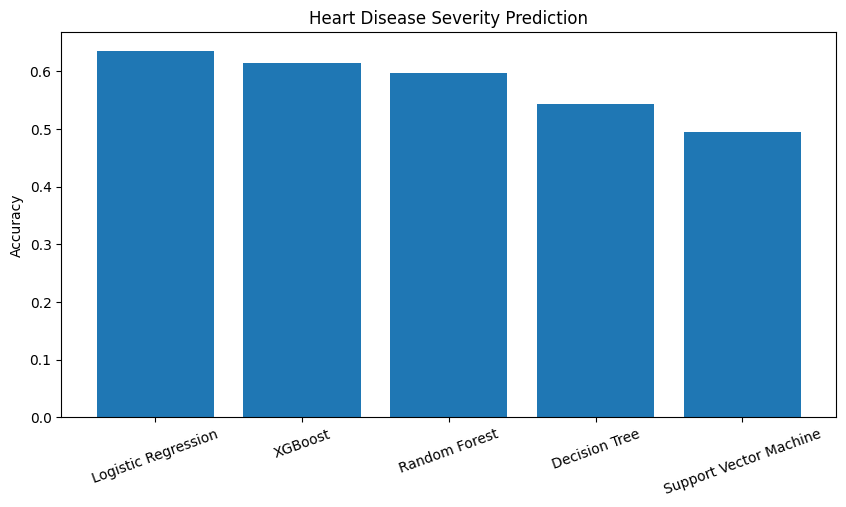

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")

plt.title("Heart Disease Severity Prediction")

plt.xticks(rotation=20)

plt.show()

In [69]:
results_df.sort_values(by="Accuracy", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6359,0.5170,0.4996,0.4899
4,XGBoost,0.6141,0.5189,0.5174,0.5164
2,Random Forest,0.5978,0.4772,0.4782,0.4745
1,Decision Tree,0.5435,0.4462,0.4462,0.4456
3,Support Vector Machine,0.4946,0.2148,0.2941,0.2319


In [71]:
import joblib

best_model = models["XGBoost"]

joblib.dump(
    best_model,
    "../saved_models/heart_severity_model.pkl"
)

print("Heart Severity Model Saved Successfully")

Heart Severity Model Saved Successfully


In [72]:
joblib.dump(
    list(X.columns),
    "../saved_models/heart_features.pkl"
)

print("Features Saved")

Features Saved


In [73]:
severity_labels = {
    0: "Healthy",
    1: "Mild",
    2: "Moderate",
    3: "Severe"
}

joblib.dump(
    severity_labels,
    "../saved_models/heart_labels.pkl"
)

print("Labels Saved")

Labels Saved


In [74]:
import os

print(os.listdir("../saved_models"))

['heart_features.pkl', 'heart_labels.pkl', 'heart_severity_model.pkl']
